# Use a custom elicitation technique

`el.quantiles`, `el.correlation` and `el.identity` cover the common
questions. For another question, define the statistic yourself with
`el.custom`. This guide asks the expert for the probability that the
outcome is larger than 10.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

## Imports

In [2]:
from typing import Any

import tensorflow as tf
import tensorflow_probability as tfp

import elicito as el

tfd = tfp.distributions

## The generative model

The outcome $y$ is normal with mean $\mu$ and standard deviation 1. We learn
the prior $\mu \sim \text{Normal}(\mu_0, \sigma_0)$.

In [3]:
class Model:
    """Normal outcome with an unknown mean"""

    def __call__(self, prior_samples: Any) -> dict[str, Any]:
        """
        Simulate the outcome

        Parameters
        ----------
        prior_samples
            samples from the prior distributions

        Returns
        -------
        :
            dictionary with the model outputs
        """
        mu = prior_samples[:, :, 0]
        ypred = tfd.Normal(loc=mu, scale=1.0).sample()
        return dict(ypred=ypred)


parameters = [
    el.parameter(
        name="mu",
        family=tfd.Normal,
        hyperparams=dict(loc=el.hyper("mu0"), scale=el.hyper("sigma0", lower=0)),
    )
]

## The custom statistic

A custom statistic is a function. Follow these rules:

- The name of the target must be the name of a model output. Here the target
  `ypred` reads the model output `ypred`.
- The function receives the target quantities by the names of its
  arguments. Here the argument `ypred` receives the target quantity
  `ypred`.
- The function returns one value for each batch, or one row of values for
  each batch. The shape is `(B,)` or `(B, k)`.
- `el.custom` has no default loss. Give one with `loss=`.

In [4]:
def prob_above_10(ypred: Any) -> Any:
    """Return the share of simulated outcomes that are larger than 10"""
    return tf.reduce_mean(tf.cast(ypred > 10.0, tf.float32), axis=1)


targets = [
    el.quantiles("y", output="ypred", probs=(0.25, 0.50, 0.75)),
    el.custom("ypred", func=prob_above_10, loss=el.losses.L2),
]

## The expert answers

The expert gives the quartiles of $y$ and the probability that $y$ is
larger than 10. The key of each answer is the name of its target.

In [5]:
expert = {"y": [6.5, 8.0, 9.5], "ypred": [0.19]}

## Training

In [6]:
eliobj = el.Elicit(Model(), targets, parameters, seeds=(2025,), epochs=400, verbose=False)

fit = eliobj.fit(expert)
fit

Method: parametric_prior (400 epochs)
Shown: replication [0] (best)

Hyperparameters:
         estimate
mu0          8.02
sigma0       1.99

Priors:
         mean         sd        q05        q95
mu       8.03       1.99       4.74       11.3

Fit to expert:
             expert   elicited      error
y[0]            6.5       6.56     0.0623
y[1]              8       8.04     0.0434
y[2]            9.5       9.53     0.0259
ypred[0]       0.19      0.189   -0.00129

Loss by target:
       technique       loss
y      quantiles      0.104
ypred     custom      0.269

Final loss:
   final_loss
0       0.373

The answers come from $\mu \sim \text{Normal}(8, 2)$. The learned
hyperparameters must be near $\mu_0 = 8$ and $\sigma_0 = 2$. The plot
compares each answer of the expert with the statistic of the model.

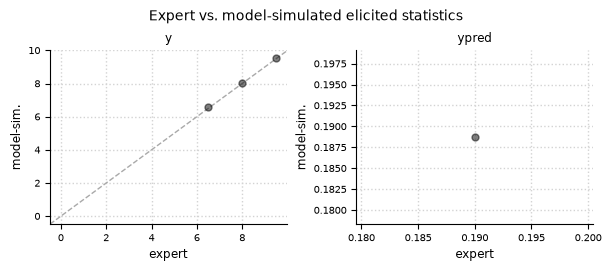

In [7]:
fit.plot.elicits(cols=2, figsize=(6, 2.6));